# 2006 — Deep Autoencoders and the Deep Learning Revival

**Papers:** Hinton & Salakhutdinov, *"Reducing the Dimensionality of Data with Neural Networks"* (Science, 2006); Hinton, Osindero & Teh, *"A Fast Learning Algorithm for Deep Belief Nets"* (2006); Bengio et al., *"Greedy Layer-Wise Training of Deep Networks"* (2006).

In 2006 deep networks were considered untrainable. These papers showed that **greedy layer-wise pre-training** (one RBM or autoencoder at a time) followed by fine-tuning with backprop makes deep nets work — the moment usually counted as the start of "deep learning".

An **autoencoder** compresses $x$ to a low-dimensional code $z = f(x)$ and reconstructs $\hat x = g(z)$, minimising $\|x - \hat x\|^2$. With a linear encoder/decoder it recovers **PCA**; with deep nonlinear layers it learns much better codes.

We do it in both styles: greedy layer-wise pre-training and then end-to-end fine-tuning, and compare a 2-D code with PCA.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
from sklearn.decomposition import PCA

Xtr, ytr, Xte, yte = load_digits_tensors()
Xtr, Xte = Xtr.flatten(1).to(device), Xte.flatten(1).to(device)
sizes = [64, 128, 64, 2]   # encoder 64 -> 128 -> 64 -> 2 (decoder mirrors it)

## Step 1: greedy layer-wise pre-training
Train a shallow autoencoder for each layer on the codes produced by the layer below.

In [3]:
def pretrain_layer(X, n_in, n_out, steps=1500, last=False):
    enc, dec = nn.Linear(n_in, n_out).to(device), nn.Linear(n_out, n_in).to(device)
    act = nn.Identity() if last else nn.Sigmoid()
    opt = torch.optim.Adam(list(enc.parameters()) + list(dec.parameters()), lr=3e-3)
    for _ in range(steps):
        idx = torch.randint(0, len(X), (128,), device=device)
        loss = F.mse_loss(dec(act(enc(X[idx]))), X[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return enc, dec, act(enc(X)), loss.item()

encs, decs, H = [], [], Xtr
for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:])):
    e, d_, H, l = pretrain_layer(H, a, b, last=(i == len(sizes) - 2))
    encs.append(e); decs.append(d_)
    print(f"layer {a}->{b}: reconstruction loss {l:.4f}")

layer 64->128: reconstruction loss 0.0003


layer 128->64: reconstruction loss 0.0008


layer 64->2: reconstruction loss 0.0123


## Step 2: unroll into a deep autoencoder and fine-tune end-to-end

In [4]:
class DeepAE(nn.Module):
    def __init__(self, encs, decs):
        super().__init__()
        self.encs, self.decs = nn.ModuleList(encs), nn.ModuleList(decs[::-1])
    def encode(self, x):
        for i, e in enumerate(self.encs):
            x = e(x) if i == len(self.encs) - 1 else torch.sigmoid(e(x))
        return x
    def decode(self, z):
        for i, d_ in enumerate(self.decs):
            z = d_(z) if i == len(self.decs) - 1 else torch.sigmoid(d_(z))
        return torch.sigmoid(z)
    def forward(self, x): return self.decode(self.encode(x))

ae = DeepAE(encs, decs).to(device)
opt = torch.optim.Adam(ae.parameters(), lr=1e-3)
for step in range(4000):
    idx = torch.randint(0, len(Xtr), (128,), device=device)
    loss = F.mse_loss(ae(Xtr[idx]), Xtr[idx])
    opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad():
    ae_err = F.mse_loss(ae(Xte), Xte).item()
    Z = ae.encode(Xte).cpu().numpy()
pca = PCA(2).fit(Xtr.cpu().numpy())
Zp = pca.transform(Xte.cpu().numpy())
pca_err = ((pca.inverse_transform(Zp) - Xte.cpu().numpy()) ** 2).mean()
print(f"test reconstruction MSE with a 2-D code — deep autoencoder: {ae_err:.4f} | PCA: {pca_err:.4f}")

test reconstruction MSE with a 2-D code — deep autoencoder: 0.0341 | PCA: 0.0532


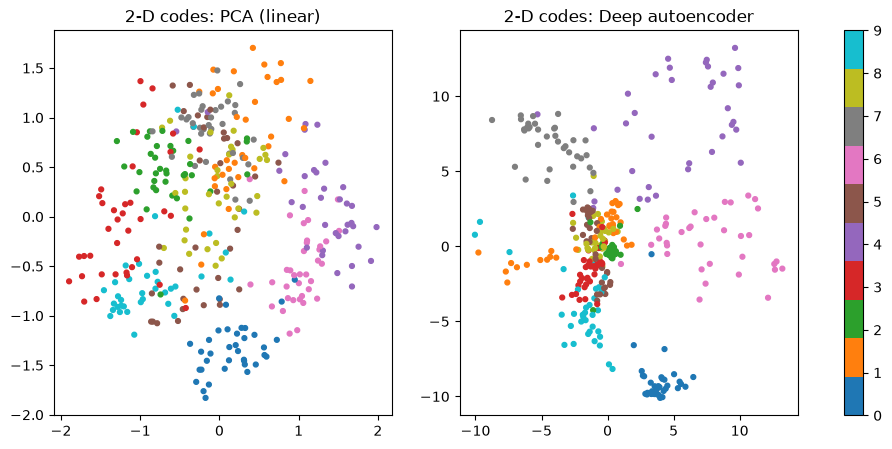

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, z, t in [(axes[0], Zp, "PCA (linear)"), (axes[1], Z, "Deep autoencoder")]:
    sc = ax.scatter(z[:, 0], z[:, 1], c=yte.numpy(), cmap="tab10", s=12)
    ax.set_title(f"2-D codes: {t}")
plt.colorbar(sc, ax=axes, ticks=range(10)); plt.show()

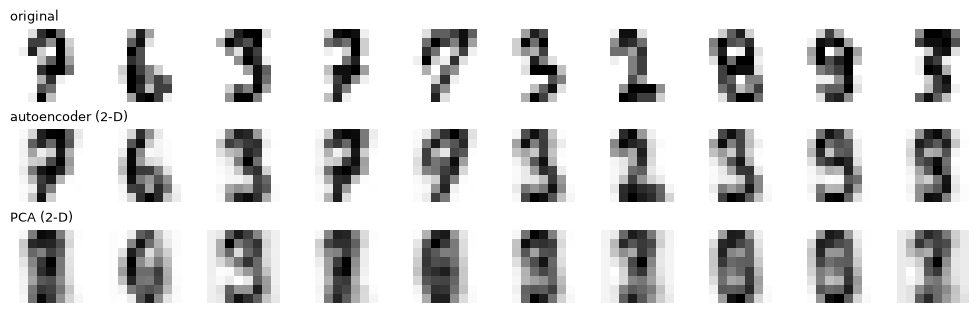

In [6]:
with torch.no_grad():
    rec = ae(Xte[:10]).cpu()
pca_rec = pca.inverse_transform(Zp[:10])
fig, axes = plt.subplots(3, 10, figsize=(10, 3.2))
for j in range(10):
    for r, img in enumerate([Xte[j].cpu(), rec[j], pca_rec[j]]):
        axes[r, j].imshow(np.asarray(img).reshape(8, 8), cmap="gray_r"); axes[r, j].axis("off")
for r, t in enumerate(["original", "autoencoder (2-D)", "PCA (2-D)"]): axes[r, 0].set_title(t, loc="left", fontsize=9)
plt.tight_layout(); plt.show()

## Takeaways
- Depth + good initialisation (then) → much better representations than linear methods.
- Later, ReLU, better initialisation and normalisation made pre-training unnecessary for supervised nets, but **unsupervised pre-training** came back at huge scale with BERT and GPT.